In [1]:

import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dataset filename
AQI_MERGED_CSV = "AQI_merged.csv"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/gdrive")
    INPUT_DIR = Path("/content/gdrive/MyDrive/SIADS_696_Milestone_II/Datasets/AQI")
else:
    INPUT_DIR = Path.cwd()
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Datasets").is_dir()), Path.cwd())

def load_file(filename, subdir, reader=pd.read_csv, **kwargs):
    candidates = [INPUT_DIR / filename, INPUT_DIR / "Datasets" / subdir / filename, REPO_ROOT / "Datasets" / subdir / filename]
    for path in candidates:
        if path.exists():
            return reader(path, **kwargs)
    raise FileNotFoundError(f"{filename} not found in {[str(p) for p in candidates]}")

aqi_target = load_file(AQI_MERGED_CSV, "AQI", float_precision="round_trip")   # exact floats, so results match an in-memory build

df = load_file(AQI_MERGED_CSV, "AQI")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (40924, 20)


,Unnamed: 0,State,County,Year,Days with AQI,Good Days,Moderate Days,Unhealthy for Sensitive Groups Days,Unhealthy Days,Very Unhealthy Days,Hazardous Days,Max AQI,90th Percentile AQI,Median AQI,Days CO,Days NO2,Days Ozone,Days PM2.5,Days PM10,Percent Moderate Days
0,0,Alabama,Autauga,1980,130,74,34,18,4,0,0,177,115,48,0,0,130,0,0,0.261538
1,1,Alabama,Jefferson,1980,348,176,109,37,19,7,0,221,140,50,212,0,136,0,0,0.313218
2,2,Alabama,Madison,1980,344,154,125,60,5,0,0,185,112,56,28,168,148,0,0,0.363372
3,3,Alabama,Mobile,1980,129,108,10,6,4,1,0,204,87,35,0,0,129,0,0,0.077519
4,4,Alabama,Monroe,1980,90,63,14,7,6,0,0,200,122,40,0,0,90,0,0,0.155556


In [2]:

import os

target = "AQI_merged.csv"
matches = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    # Skip folders that are unlikely to contain your dataset
    dirs[:] = [d for d in dirs if d not in {
        '.git', '.ipynb_checkpoints', 'node_modules'
    }]

    for filename in files:
        if filename.lower() == target.lower():
            matches.append(os.path.join(root, filename))

if matches:
    print("Found the dataset:")
    for path in matches:
        print(path)
else:
    print("Dataset not found in MyDrive.")
    print("Check whether the CSV is uploaded to Google Drive.")


Dataset not found in MyDrive.
Check whether the CSV is uploaded to Google Drive.


In [3]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

Rows: 40924
Columns: 20

Column names:
['Unnamed: 0', 'State', 'County', 'Year', 'Days with AQI', 'Good Days', 'Moderate Days', 'Unhealthy for Sensitive Groups Days', 'Unhealthy Days', 'Very Unhealthy Days', 'Hazardous Days', 'Max AQI', '90th Percentile AQI', 'Median AQI', 'Days CO', 'Days NO2', 'Days Ozone', 'Days PM2.5', 'Days PM10', 'Percent Moderate Days']

Data types:
Unnamed: 0                               int64
State                                   object
County                                  object
Year                                     int64
Days with AQI                            int64
Good Days                                int64
Moderate Days                            int64
Unhealthy for Sensitive Groups Days      int64
Unhealthy Days                           int64
Very Unhealthy Days                      int64
Hazardous Days                           int64
Max AQI                                  int64
90th Percentile AQI                      int64
Median AQI   

In [4]:
df = df.drop(columns=["Unnamed: 0"])

df.head()

,State,County,Year,Days with AQI,Good Days,Moderate Days,Unhealthy for Sensitive Groups Days,Unhealthy Days,Very Unhealthy Days,Hazardous Days,Max AQI,90th Percentile AQI,Median AQI,Days CO,Days NO2,Days Ozone,Days PM2.5,Days PM10,Percent Moderate Days
0,Alabama,Autauga,1980,130,74,34,18,4,0,0,177,115,48,0,0,130,0,0,0.261538
1,Alabama,Jefferson,1980,348,176,109,37,19,7,0,221,140,50,212,0,136,0,0,0.313218
2,Alabama,Madison,1980,344,154,125,60,5,0,0,185,112,56,28,168,148,0,0,0.363372
3,Alabama,Mobile,1980,129,108,10,6,4,1,0,204,87,35,0,0,129,0,0,0.077519
4,Alabama,Monroe,1980,90,63,14,7,6,0,0,200,122,40,0,0,90,0,0,0.155556


In [5]:
print(df.shape)

(40924, 19)


In [6]:
missing_values = df.isnull().sum()

print(missing_values)

State                                  0
County                                 0
Year                                   0
Days with AQI                          0
Good Days                              0
Moderate Days                          0
Unhealthy for Sensitive Groups Days    0
Unhealthy Days                         0
Very Unhealthy Days                    0
Hazardous Days                         0
Max AQI                                0
90th Percentile AQI                    0
Median AQI                             0
Days CO                                0
Days NO2                               0
Days Ozone                             0
Days PM2.5                             0
Days PM10                              0
Percent Moderate Days                  0
dtype: int64


In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values detected in the dataset.")
else:
    plt.figure(figsize=(12, 6))
    plt.bar(missing.index.astype(str), missing.values)
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

No missing values detected in the dataset.


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
df[df.duplicated()].head()

,State,County,Year,Days with AQI,Good Days,Moderate Days,Unhealthy for Sensitive Groups Days,Unhealthy Days,Very Unhealthy Days,Hazardous Days,Max AQI,90th Percentile AQI,Median AQI,Days CO,Days NO2,Days Ozone,Days PM2.5,Days PM10,Percent Moderate Days


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,40924.0,2004.215350,11.961369,1980.0,1995.000000,2005.000000,2014.000000,2024.0
Days with AQI,40924.0,281.615678,109.110163,1.0,212.000000,354.000000,365.000000,366.0
Good Days,40924.0,193.279591,92.641734,0.0,118.000000,201.000000,270.000000,366.0
Moderate Days,40924.0,76.326141,65.099678,0.0,27.000000,61.000000,110.000000,359.0
Unhealthy for Sensitive Groups Days,40924.0,8.917432,13.480665,0.0,0.000000,3.000000,13.000000,170.0
Unhealthy Days,40924.0,2.471117,6.424756,0.0,0.000000,0.000000,2.000000,114.0
Very Unhealthy Days,40924.0,0.587479,4.578972,0.0,0.000000,0.000000,0.000000,160.0
Hazardous Days,40924.0,0.033917,0.586711,0.0,0.000000,0.000000,0.000000,37.0
Max AQI,40924.0,140.446217,251.904021,6.0,90.000000,126.000000,170.000000,22897.0
90th Percentile AQI,40924.0,70.525217,28.062047,4.0,53.000000,66.000000,84.000000,510.0


In [11]:
print("First year:", df["Year"].min())
print("Last year:", df["Year"].max())

print("\nNumber of observations by year:")
print(df["Year"].value_counts().sort_index())

First year: 1980
Last year: 2024

Number of observations by year:
Year
1980     462
1981     482
1982     484
1983     491
1984     477
1985     546
1986     568
1987     610
1988     671
1989     732
1990     821
1991     865
1992     898
1993     916
1994     938
1995     967
1996     973
1997     994
1998     952
1999    1023
2000    1080
2001    1097
2002    1105
2003    1112
2004    1097
2005    1091
2006    1071
2007    1062
2008    1059
2009    1061
2010    1063
2011    1055
2012    1034
2013    1028
2014    1020
2015    1029
2016    1016
2017    1014
2018    1009
2019    1008
2020     990
2021     991
2022     992
2023     983
2024     987
Name: count, dtype: int64


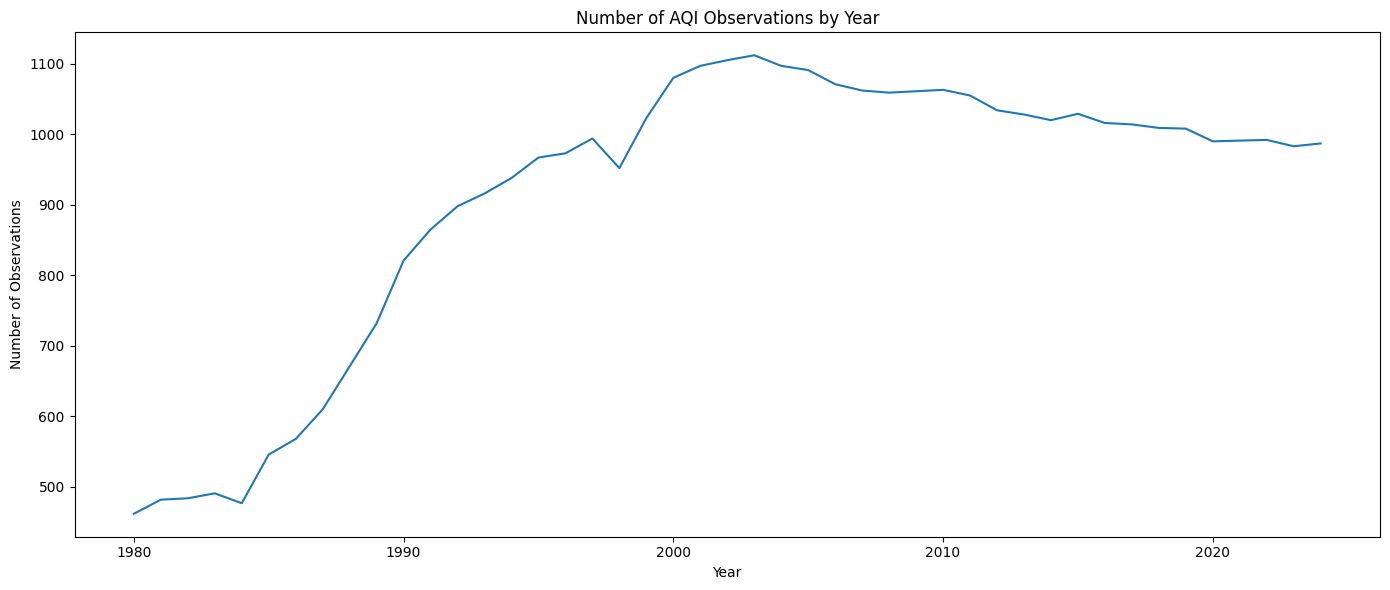

In [12]:
year_counts = df["Year"].value_counts().sort_index()

plt.figure(figsize=(14, 6))

plt.plot(year_counts.index, year_counts.values)

plt.title("Number of AQI Observations by Year")
plt.xlabel("Year")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [13]:
state_counts = df["State"].value_counts()

print(state_counts)

State
California              2312
Ohio                    1714
North Carolina          1658
Virginia                1543
Texas                   1493
Pennsylvania            1462
Indiana                 1378
New York                1343
Kentucky                1335
Florida                 1324
Wisconsin               1282
Colorado                1188
Michigan                1158
Illinois                1048
Georgia                 1044
Tennessee               1026
Washington              1020
Louisiana                942
South Carolina           863
Montana                  791
Oregon                   782
Alabama                  782
Minnesota                773
Missouri                 765
New Jersey               748
Oklahoma                 737
Idaho                    672
New Mexico               656
Iowa                     650
Maryland                 642
Wyoming                  583
Arkansas                 583
West Virginia            560
Mississippi              530
Arizona 

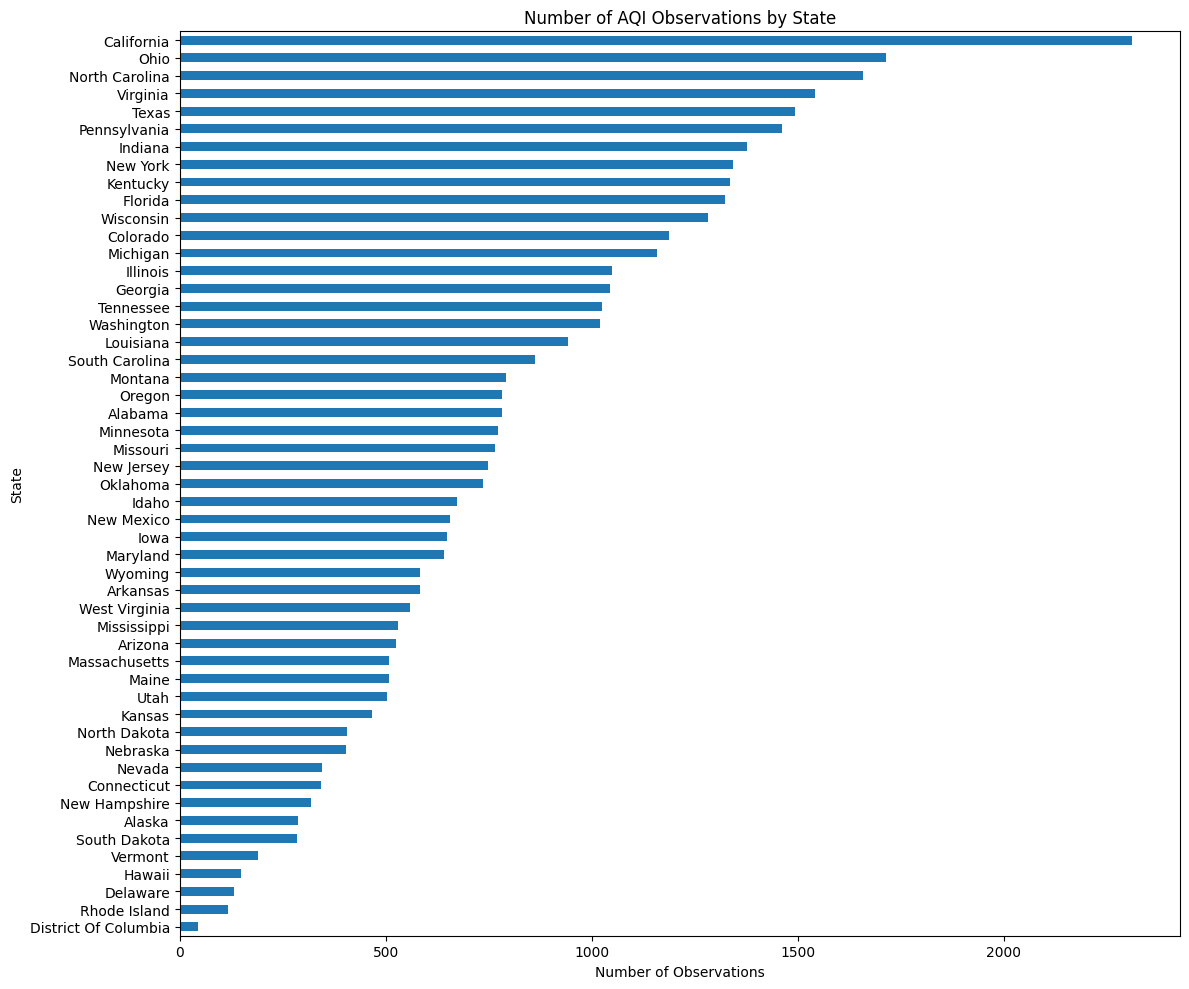

In [14]:
plt.figure(figsize=(12, 10))

state_counts.sort_values().plot(kind="barh")

plt.title("Number of AQI Observations by State")
plt.xlabel("Number of Observations")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [15]:
counties_by_state = (
    df.groupby("State")["County"]
      .nunique()
      .sort_values()
)

print(counties_by_state)

State
District Of Columbia     1
Rhode Island             3
Delaware                 3
Hawaii                   4
Vermont                  7
Connecticut              8
New Hampshire           10
Nevada                  12
Massachusetts           13
South Dakota            14
Arizona                 15
North Dakota            15
Alaska                  16
Maine                   17
Maryland                19
Utah                    19
West Virginia           20
New Jersey              20
New Mexico              21
Wyoming                 21
Kansas                  23
Nebraska                24
Iowa                    25
Oregon                  26
Arkansas                26
South Carolina          28
Mississippi             29
Louisiana               30
Alabama                 31
Idaho                   31
Illinois                33
Washington              34
Missouri                34
Montana                 36
Georgia                 39
New York                39
Minnesota             

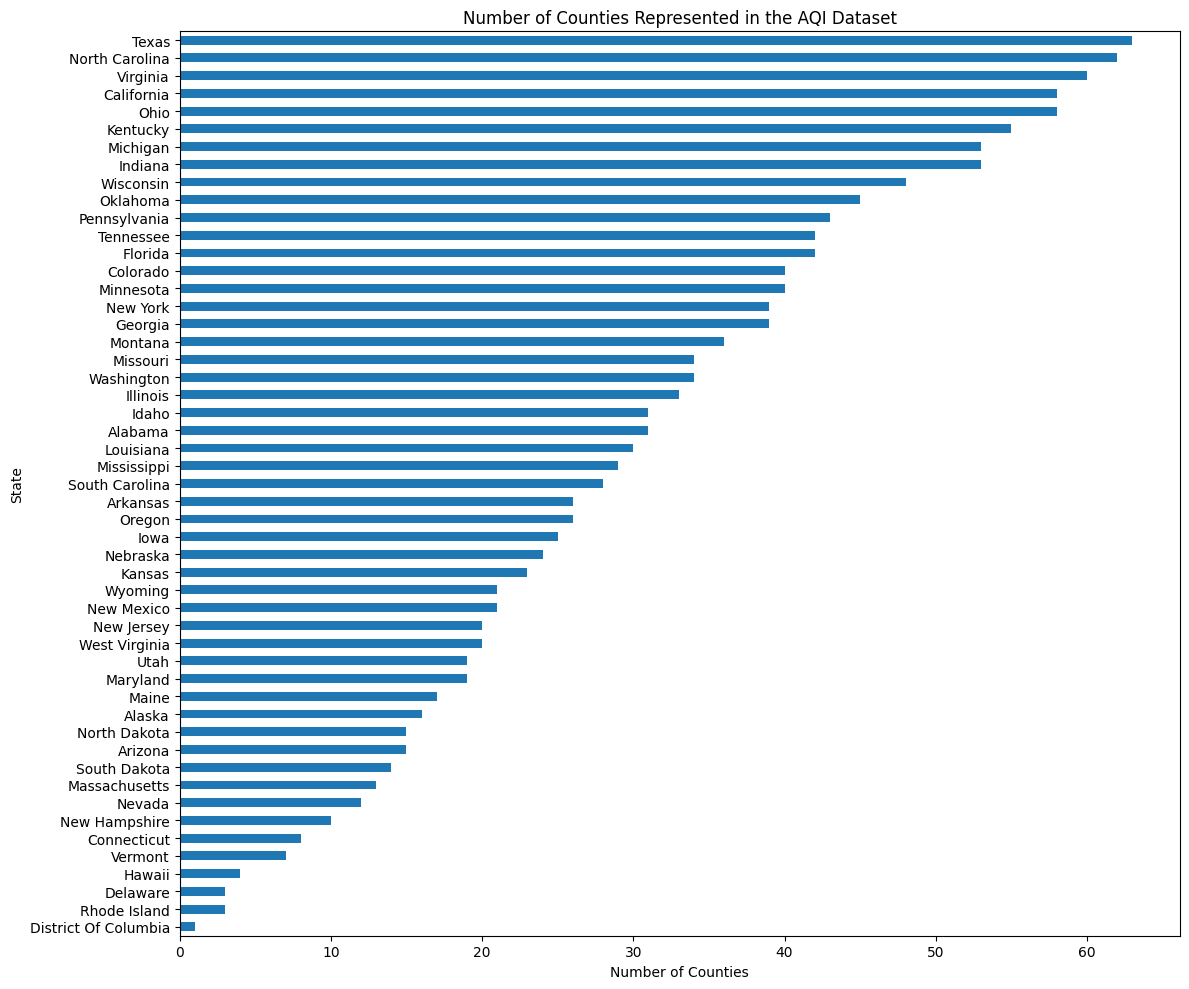

In [16]:
plt.figure(figsize=(12, 10))

counties_by_state.plot(kind="barh")

plt.title("Number of Counties Represented in the AQI Dataset")
plt.xlabel("Number of Counties")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [17]:
county_counts = (
    df.groupby(["State", "County"])
      .size()
      .reset_index(name="Observations")
)

county_counts.head()

,State,County,Observations
0,Alabama,Autauga,5
1,Alabama,Baldwin,25
2,Alabama,Barbour,4
3,Alabama,Calhoun,9
4,Alabama,Clay,34


In [18]:
county_counts_sorted = county_counts.sort_values("Observations")

county_counts_sorted.head(25)

,State,County,Observations
1408,Washington,San Juan,1
649,Minnesota,Hubbard,1
476,Kentucky,Larue,1
64,Arkansas,Benton,1
772,Montana,Teton,1
1506,Wyoming,Washakie,1
615,Michigan,Montcalm,1
1256,Texas,Fort Bend,1
1380,Virginia,Washington,1
1258,Texas,Gillespie,1


In [19]:
state_year_counts = (
    df.groupby(["State", "Year"])
      .size()
      .reset_index(name="Observations")
)

heatmap_data = state_year_counts.pivot(
    index="State",
    columns="Year",
    values="Observations"
)

heatmap_data = heatmap_data.fillna(0)

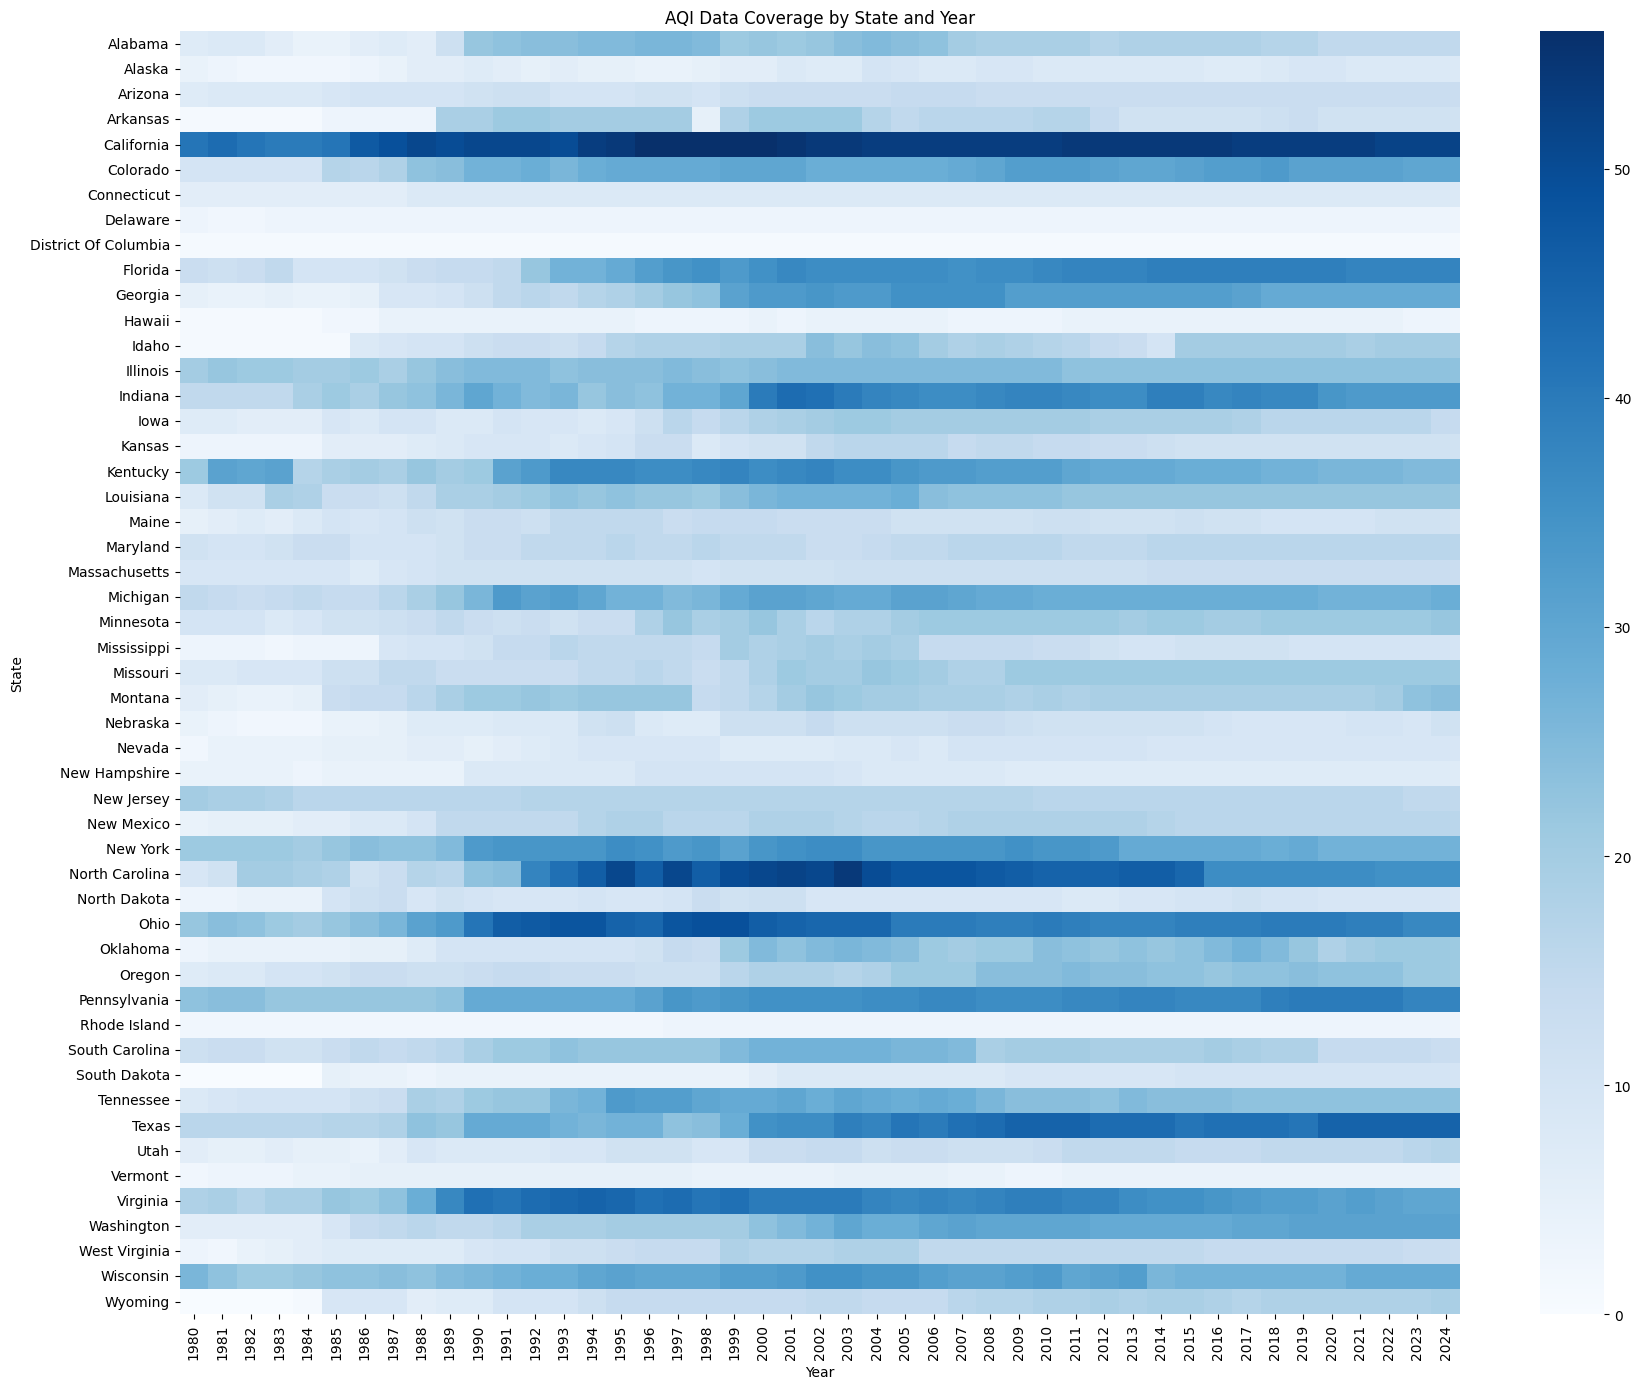

In [20]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    heatmap_data,
    cmap="Blues"
)

plt.title("AQI Data Coverage by State and Year")
plt.xlabel("Year")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [21]:
aqi_variables = [
    "Max AQI",
    "90th Percentile AQI",
    "Median AQI"
]

df[aqi_variables].describe()

,Max AQI,90th Percentile AQI,Median AQI
count,40924.000000,40924.000000,40924.000000
mean,140.446217,70.525217,39.649130
std,251.904021,28.062047,13.172487
min,6.000000,4.000000,0.000000
25%,90.000000,53.000000,33.000000
50%,126.000000,66.000000,41.000000
75%,170.000000,84.000000,47.000000
max,22897.000000,510.000000,192.000000


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


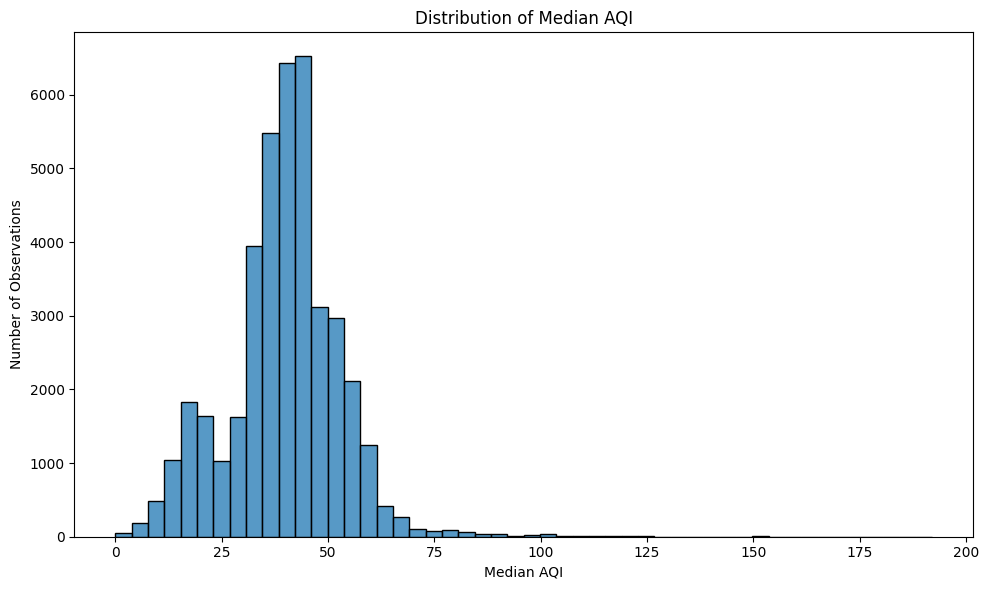

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Median AQI",
    bins=50
)

plt.title("Distribution of Median AQI")
plt.xlabel("Median AQI")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [23]:
category_columns = [
    "Good Days",
    "Moderate Days",
    "Unhealthy for Sensitive Groups Days",
    "Unhealthy Days",
    "Very Unhealthy Days",
    "Hazardous Days"
]

category_totals = df[category_columns].sum().sort_values(ascending=False)

print(category_totals)

Good Days                              7909774
Moderate Days                          3123571
Unhealthy for Sensitive Groups Days     364937
Unhealthy Days                          101128
Very Unhealthy Days                      24042
Hazardous Days                            1388
dtype: int64


In [24]:
pollutant_columns = [
    "Days CO",
    "Days NO2",
    "Days Ozone",
    "Days PM2.5",
    "Days PM10"
]

pollutant_totals = df[pollutant_columns].sum().sort_values(ascending=False)

print(pollutant_totals)

Days Ozone    6177283
Days PM2.5    3339417
Days PM10      785857
Days NO2       710780
Days CO        511503
dtype: int64


In [25]:
pollutant_data = df[pollutant_columns]

correlation_matrix = pollutant_data.corr()

print(correlation_matrix)

             Days CO  Days NO2  Days Ozone  Days PM2.5  Days PM10
Days CO     1.000000  0.058486   -0.106850   -0.169236  -0.010611
Days NO2    0.058486  1.000000   -0.067565   -0.168271  -0.053834
Days Ozone -0.106850 -0.067565    1.000000   -0.399292  -0.310768
Days PM2.5 -0.169236 -0.168271   -0.399292    1.000000  -0.180024
Days PM10  -0.010611 -0.053834   -0.310768   -0.180024   1.000000


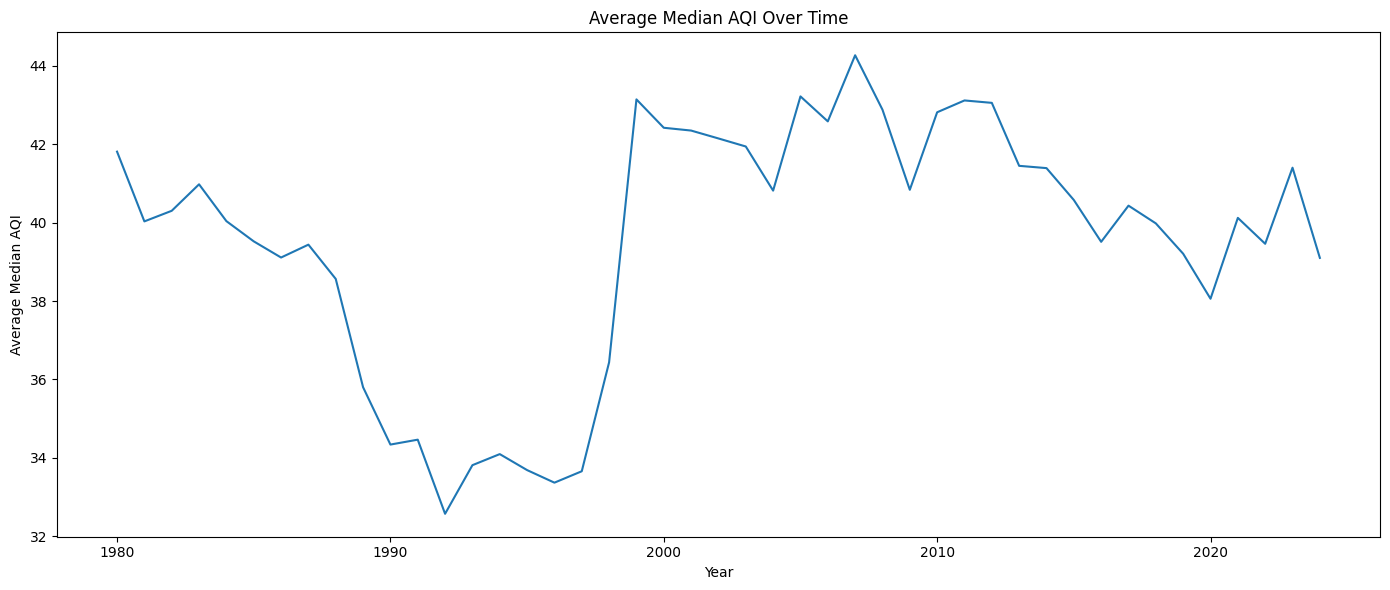

In [26]:
yearly_aqi = (
    df.groupby("Year")["Median AQI"]
      .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_aqi.index,
    yearly_aqi.values
)

plt.title("Average Median AQI Over Time")
plt.xlabel("Year")
plt.ylabel("Average Median AQI")

plt.tight_layout()
plt.show()

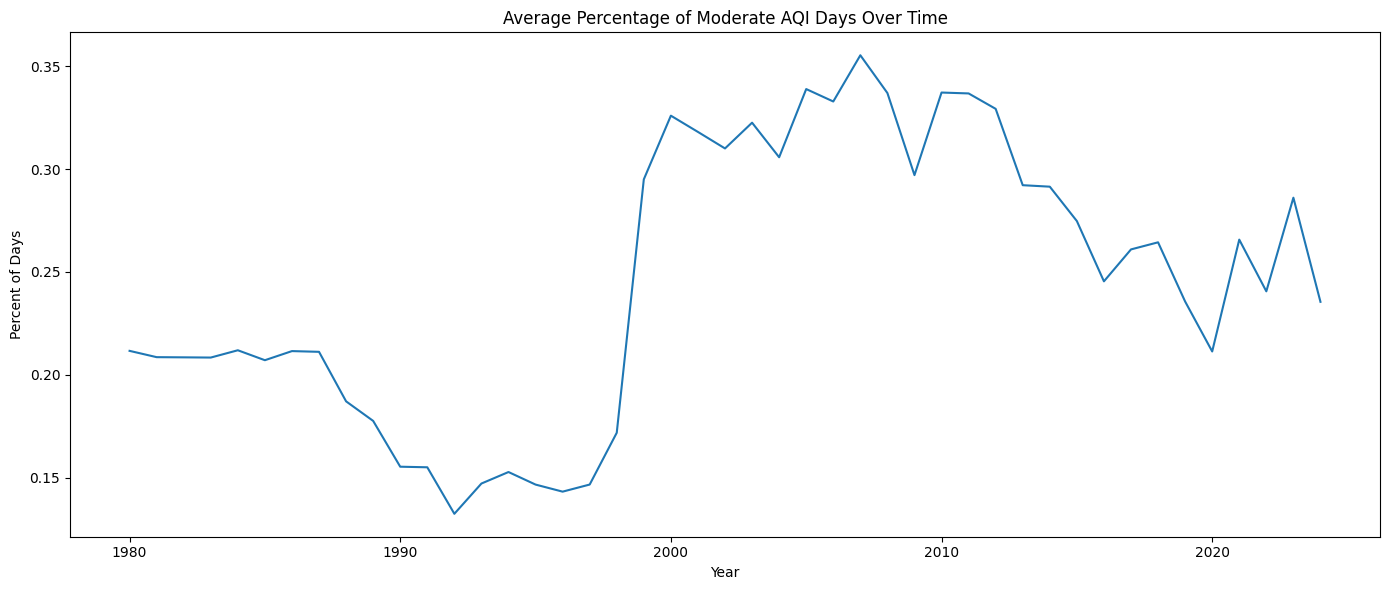

In [27]:
yearly_moderate = (
    df.groupby("Year")["Percent Moderate Days"]
      .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_moderate.index,
    yearly_moderate.values
)

plt.title("Average Percentage of Moderate AQI Days Over Time")
plt.xlabel("Year")
plt.ylabel("Percent of Days")

plt.tight_layout()
plt.show()

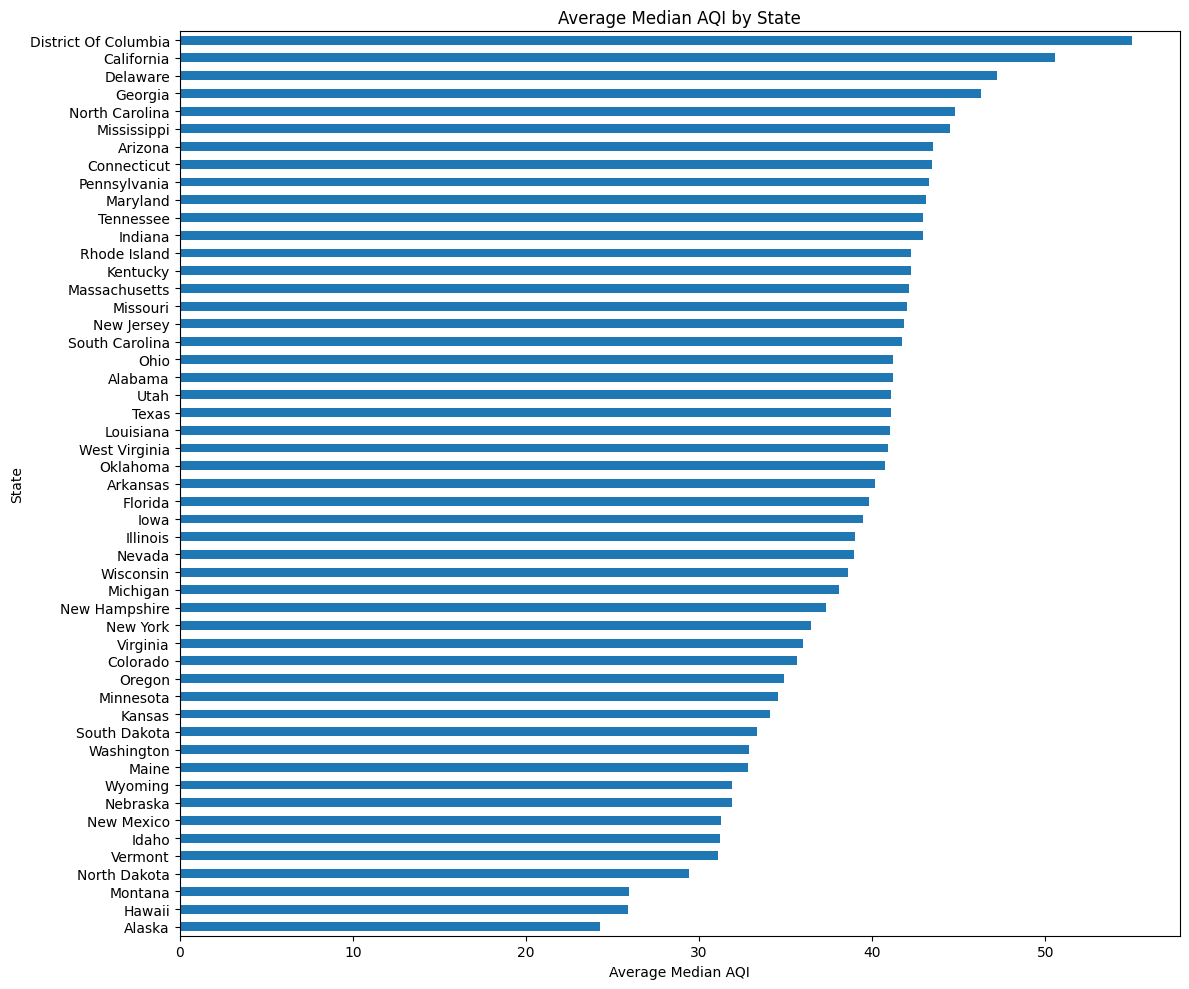

In [28]:
state_aqi = (
    df.groupby("State")["Median AQI"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(12, 10))

state_aqi.plot(kind="barh")

plt.title("Average Median AQI by State")
plt.xlabel("Average Median AQI")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [29]:
state_year_aqi = (
    df.groupby(["State", "Year"])["Median AQI"]
      .mean()
      .reset_index()
)

aqi_heatmap = state_year_aqi.pivot(
    index="State",
    columns="Year",
    values="Median AQI"
)

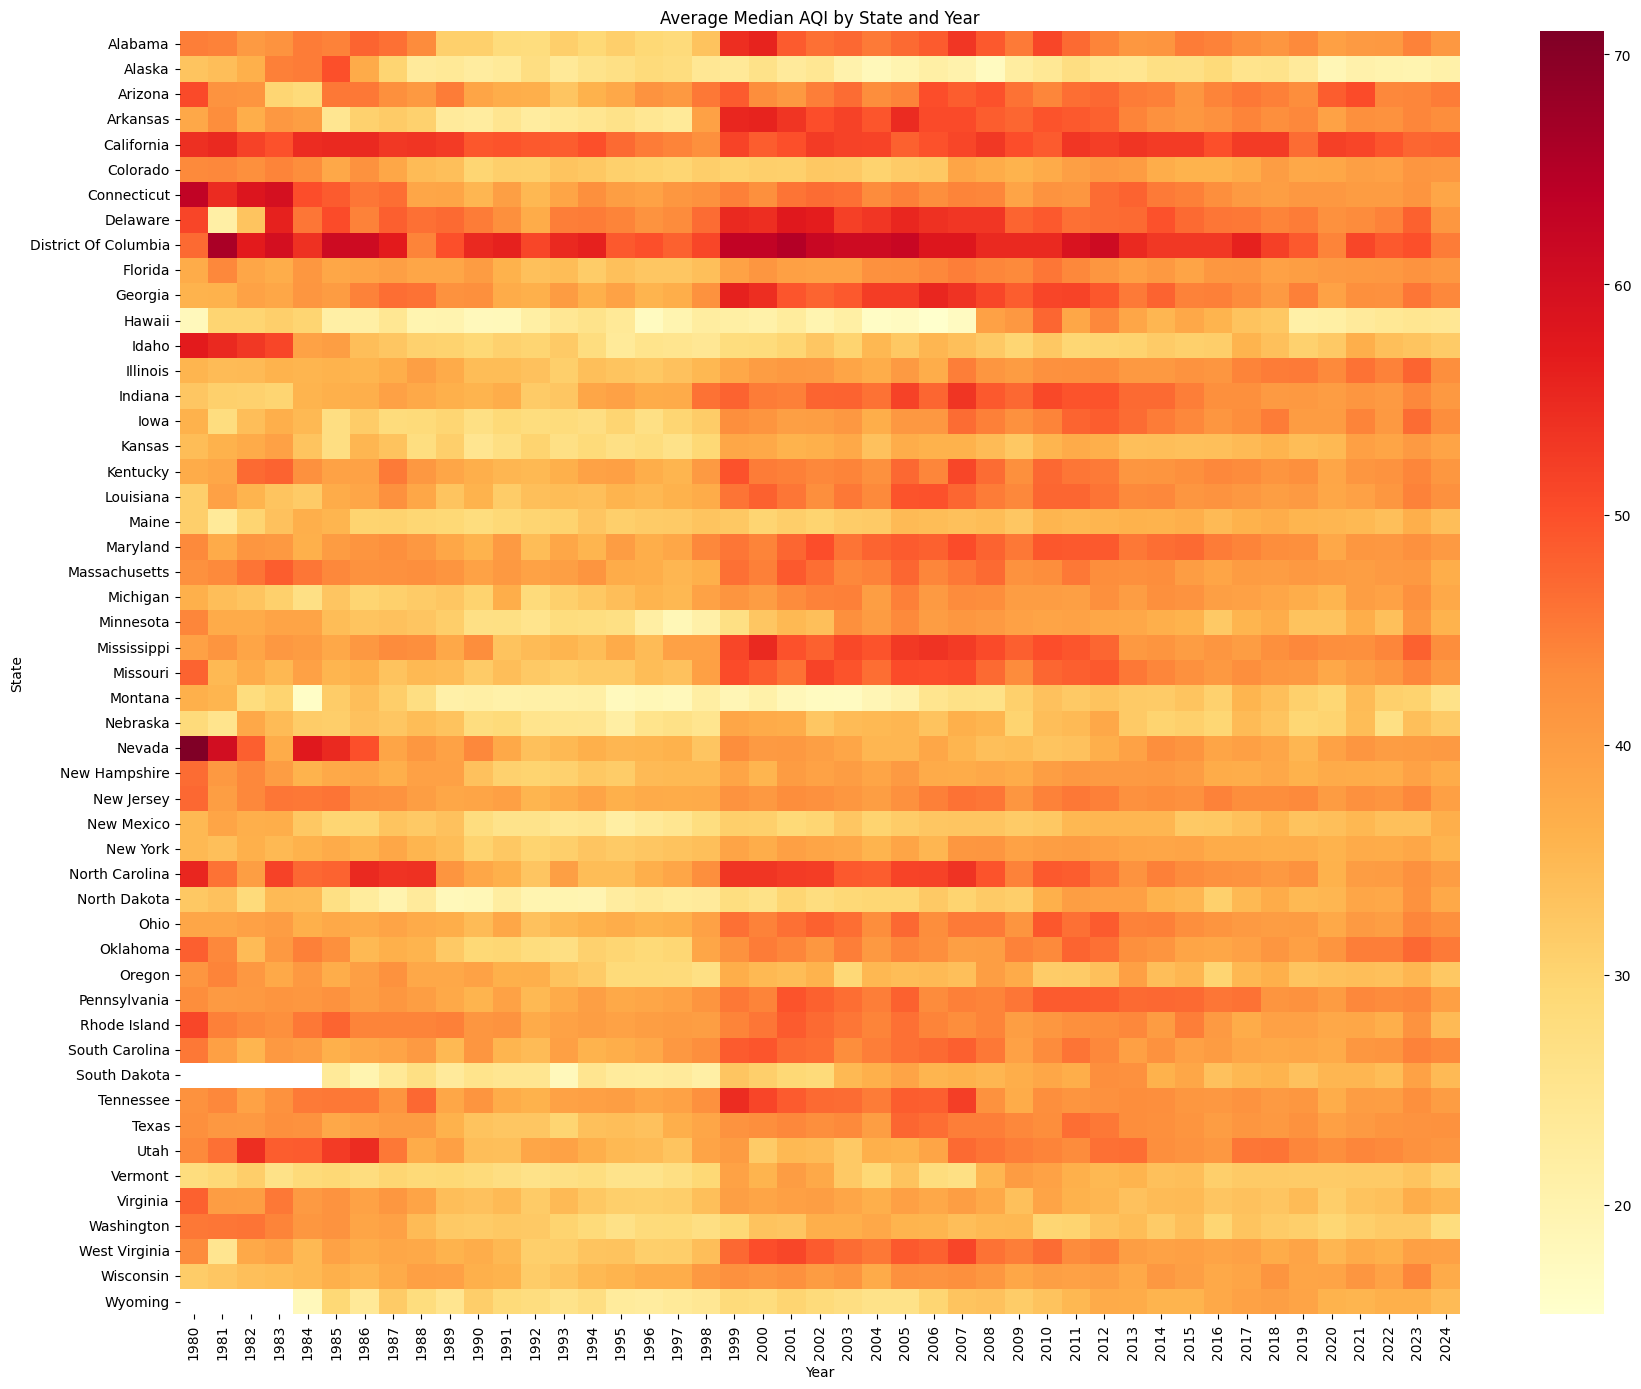

In [30]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    aqi_heatmap,
    cmap="YlOrRd"
)

plt.title("Average Median AQI by State and Year")
plt.xlabel("Year")
plt.ylabel("State")

plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


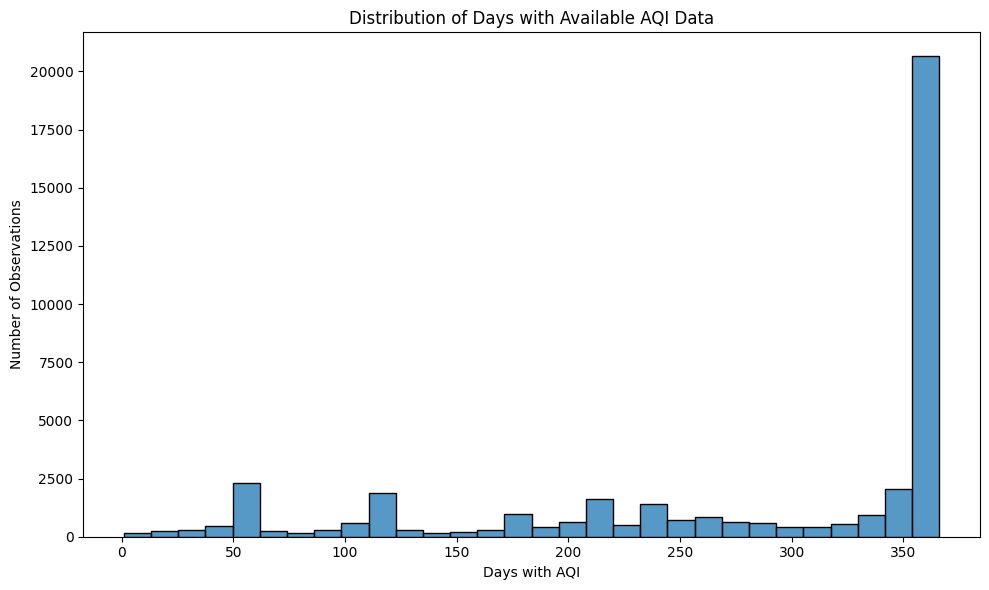

In [31]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Days with AQI",
    bins=30
)

plt.title("Distribution of Days with Available AQI Data")
plt.xlabel("Days with AQI")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [32]:
coverage_summary = (
    df.groupby("State")
      .agg(
          Observations=("County", "size"),
          Counties=("County", "nunique"),
          First_Year=("Year", "min"),
          Last_Year=("Year", "max"),
          Avg_Days_AQI=("Days with AQI", "mean"),
          Avg_Median_AQI=("Median AQI", "mean")
      )
      .sort_values("Observations", ascending=False)
)

coverage_summary

,Observations,Counties,First_Year,Last_Year,Avg_Days_AQI,Avg_Median_AQI
State,,,,,,
California,2312,58,1980,2024,339.452422,50.535035
Ohio,1714,58,1980,2024,271.352975,41.215286
North Carolina,1658,62,1980,2024,246.914958,44.781062
Virginia,1543,60,1980,2024,236.681141,35.974076
Texas,1493,63,1980,2024,317.111855,41.071668
Pennsylvania,1462,43,1980,2024,341.351573,43.259918
Indiana,1378,53,1980,2024,257.728592,42.928157
New York,1343,39,1980,2024,322.272524,36.441549
Kentucky,1335,55,1980,2024,270.735581,42.218727
